# Plotly basics — California Housing
## 1. Task
Explore what drives house prices across California districts with interactive plotly charts.
## 2. Data

In [1]:
import pandas as pd
import plotly.express as px
from sklearn.datasets import fetch_california_housing

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

## hist

In [ ]:
df['price_usd'] = df['MedHouseVal']*100000

fig = px.histogram(df, x='price_usd', nbins=50,
                   title='Distibution of median house value')
fig.update_layout(xaxis_title='Median house value, $',
                  yaxis_title='Number of disticts')
fig.show()

## scatter

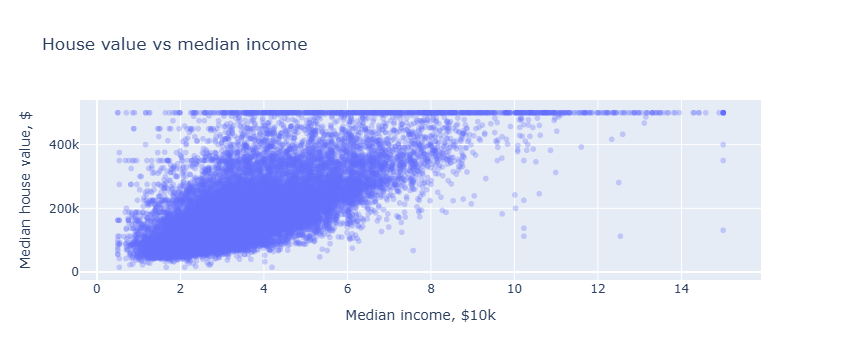

In [10]:
fig = px.scatter(df, x='MedInc', y='price_usd', opacity=0.3,
                 hover_data=['HouseAge', 'AveRooms', 'Population'],
                 title='House value vs median income')

fig.update_layout(xaxis_title='Median income, $10k',
                  yaxis_title='Median house value, $')

fig.show()

## price by coordinates

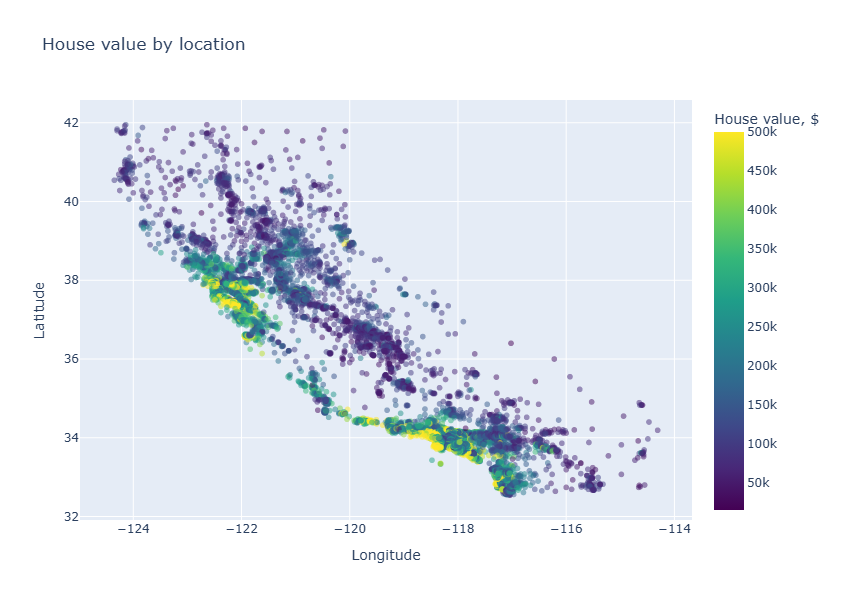

In [14]:
fig = px.scatter(df, x='Longitude', y='Latitude', color='price_usd',
                 color_continuous_scale='Viridis', opacity=0.5,
                 labels={'price_usd':'House value, $'},
                 title='House value by location')

fig.update_layout(width=640, height=600)

fig.show()

## experiment

In [17]:
capped = df['MedHouseVal']>=5
df_clean = df[~capped]

print('Capped districts: ', capped.sum())
print('Corr, all data: ', round(df['MedInc'].corr(df['price_usd']),3))
print('Corr, no capped: ',round(df_clean['MedInc'].corr(df['price_usd']),3))
print('Mean price, all :', round(df['price_usd'].mean()))
print('Mean price, no capped :', round(df_clean['price_usd'].mean()))

Capped districts:  992
Corr, all data:  0.688
Corr, no capped:  0.647
Mean price, all : 206856
Mean price, no capped : 192055


## 5. What I learned
- plotly draws interactive charts (hover, zoom, legend toggle); `px` works like seaborn: DataFrame + column names. `labels` renames axes and hover, `update_layout` changes title, size and other layout.
- Data can be capped: house value at $500k, income at 15 ($150k), house age at 52. Capped values hide the real numbers, so check units and caps before any analysis.
- Removing capped districts lowered the income–price correlation: narrower range of data means weaker visible correlation (restriction of range). Dropping rows is a decision that changes conclusions.